In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

data_path = '/content/drive/MyDrive/personality_synthetic_dataset.csv'
df = pd.read_csv(data_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.drop_duplicates(inplace=True)
print("Dataset shape after removing duplicates:", df.shape)
df.head()

Dataset shape after removing duplicates: (20000, 30)


,personality_type,social_energy,alone_time_preference,talkativeness,deep_reflection,group_comfort,party_liking,listening_skill,empathy,creativity,...,spontaneity,adventurousness,reading_habit,sports_interest,online_social_usage,travel_desire,gadget_usage,work_style_collaborative,decision_speed,stress_handling
0,Extrovert,6.794295,3.854670,8.725446,2.515151,7.097368,8.588762,6.774799,6.430132,6.142968,...,4.853313,8.257134,5.270555,10.000000,9.154296,4.816422,9.191711,8.313590,8.032376,7.176905
1,Ambivert,6.378988,5.731157,7.029529,7.274493,4.111199,3.258248,5.550909,3.958179,6.149457,...,6.067201,6.289347,5.753165,5.334303,4.683781,4.725666,5.956141,5.890619,3.158988,3.423577
2,Ambivert,7.459421,6.322263,3.922269,4.622261,5.343276,7.452152,9.483990,6.127654,7.032017,...,5.524244,9.238784,5.250405,3.153540,5.000338,6.139166,6.033048,5.807500,4.571003,5.647480
3,Extrovert,6.159626,3.097837,6.019093,1.965440,7.837140,10.000000,9.436733,8.949684,8.923875,...,4.327018,8.489791,5.312617,8.379936,7.601946,6.370056,5.410145,6.671781,6.600233,5.870088
4,Introvert,5.568462,6.986722,3.913240,9.926161,1.650483,0.362298,7.470387,6.756837,9.507803,...,5.187689,3.167217,7.060235,2.333388,7.771569,5.534336,5.704598,5.832968,5.813099,3.758084


In [ ]:
print("Missing values in dataset:\n", df.isnull().sum())

Missing values in dataset:
 personality_type            0
social_energy               0
alone_time_preference       0
talkativeness               0
deep_reflection             0
group_comfort               0
party_liking                0
listening_skill             0
empathy                     0
creativity                  0
organization                0
leadership                  0
risk_taking                 0
public_speaking_comfort     0
curiosity                   0
routine_preference          0
excitement_seeking          0
friendliness                0
emotional_stability         0
planning                    0
spontaneity                 0
adventurousness             0
reading_habit               0
sports_interest             0
online_social_usage         0
travel_desire               0
gadget_usage                0
work_style_collaborative    0
decision_speed              0
stress_handling             0
dtype: int64


In [ ]:
df.nunique()

,0
personality_type,3
social_energy,19254
alone_time_preference,19249
talkativeness,19214
deep_reflection,19374
group_comfort,19345
party_liking,18790
listening_skill,19238
empathy,19753
creativity,19917


In [ ]:
stats = df.describe().T
print("Descriptive Statistics (Excerpt):")
display(stats[['mean', 'std', 'min', '50%', 'max']])

Descriptive Statistics (Excerpt):


,mean,std,min,50%,max
social_energy,5.509190,2.468526,0.000000,5.540706,10.0
alone_time_preference,5.454690,2.493731,0.000000,5.464038,10.0
talkativeness,5.525955,2.488006,0.000000,5.574786,10.0
deep_reflection,5.958689,2.162427,0.000000,5.972345,10.0
group_comfort,6.014381,2.178551,0.000000,6.051489,10.0
party_liking,5.040063,2.810563,0.000000,5.053005,10.0
listening_skill,6.964450,1.647944,1.308044,6.989855,10.0
empathy,6.483220,1.534911,0.804853,6.481365,10.0
creativity,5.996018,1.496690,0.000000,6.003320,10.0
organization,5.973280,1.697589,0.000000,5.986871,10.0


/tmp/ipykernel_683/1626775827.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='personality_type', data=df, palette='viridis')


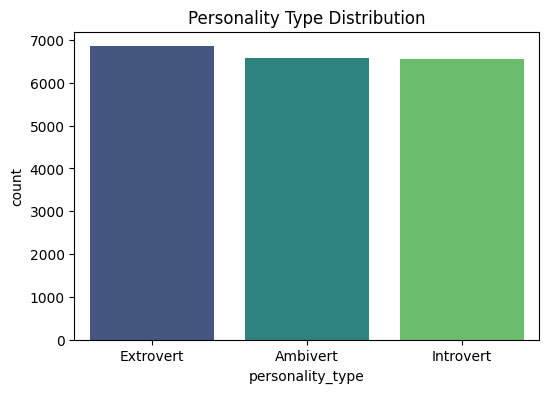

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='personality_type', data=df, palette='viridis')
plt.title("Personality Type Distribution")
plt.show()

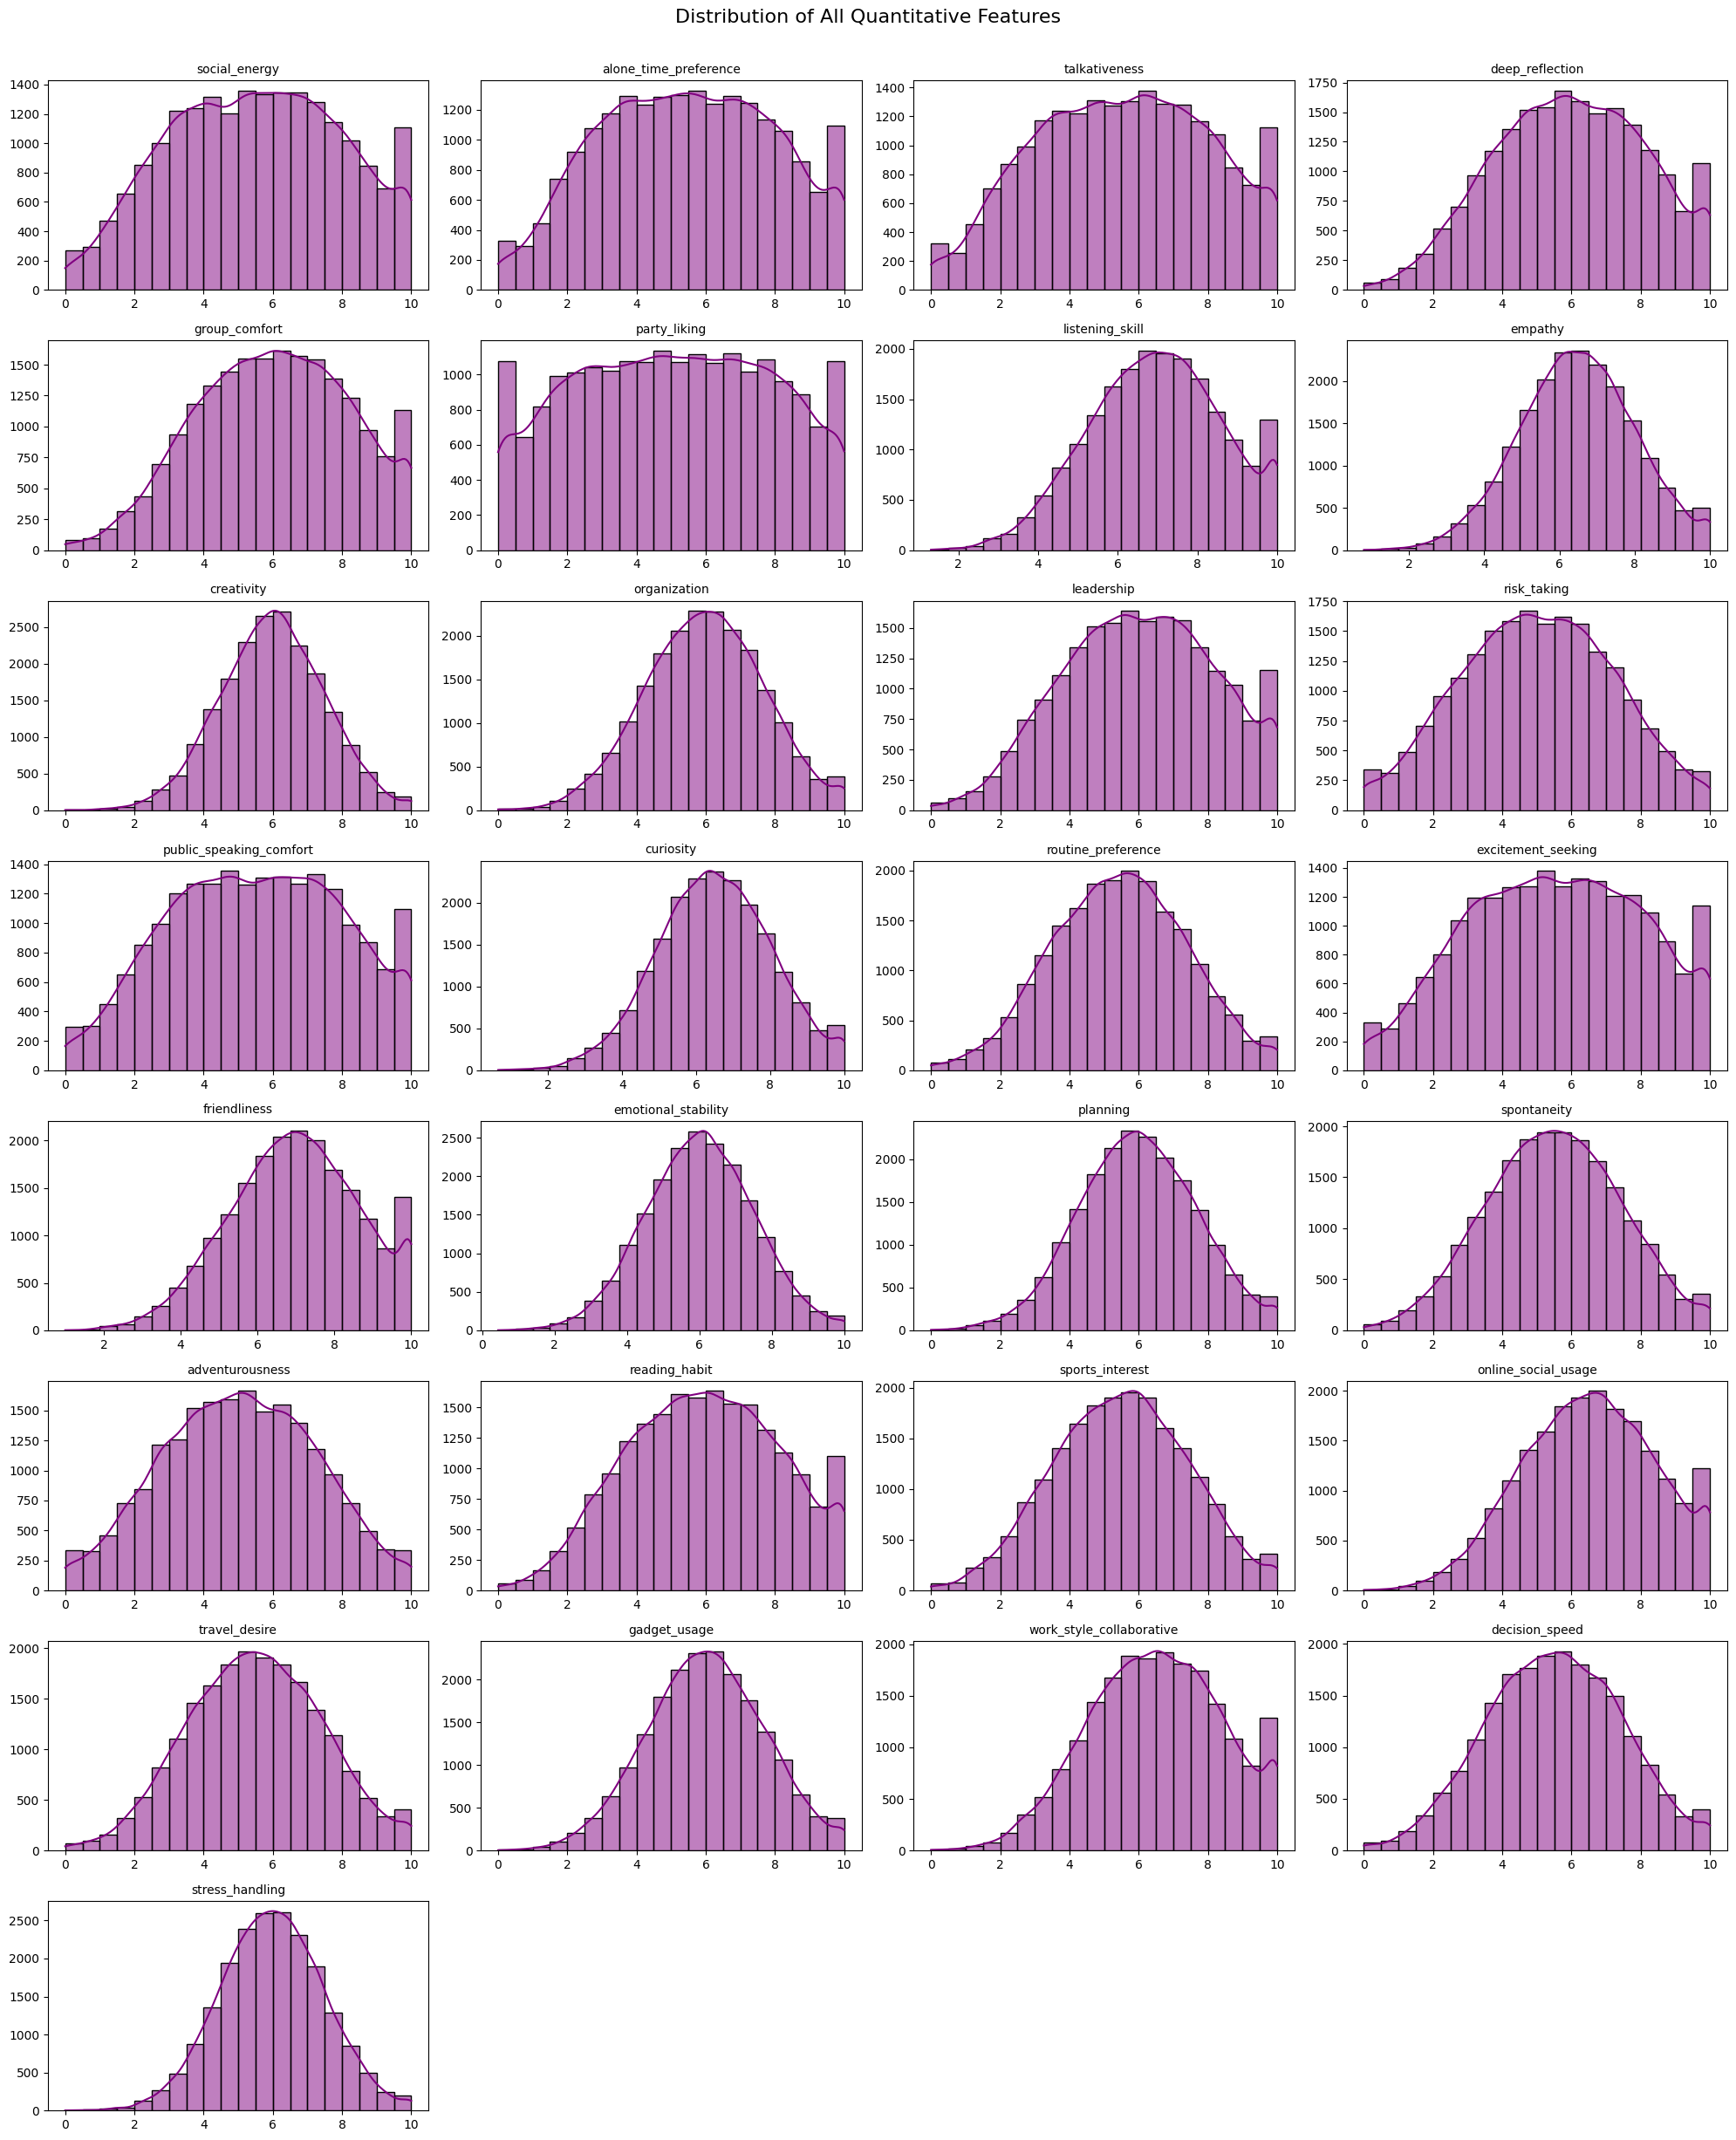

In [ ]:
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns

plt.figure(figsize=(20, 24))

for i, col in enumerate(numerical_cols):
    plt.subplot(8, 4, i + 1)
    sns.histplot(df[col], kde=True, bins=20, color='purple', edgecolor='black')
    plt.title(col, fontsize=10)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.suptitle('Distribution of All Quantitative Features', y=1.02, fontsize=16)
plt.show()

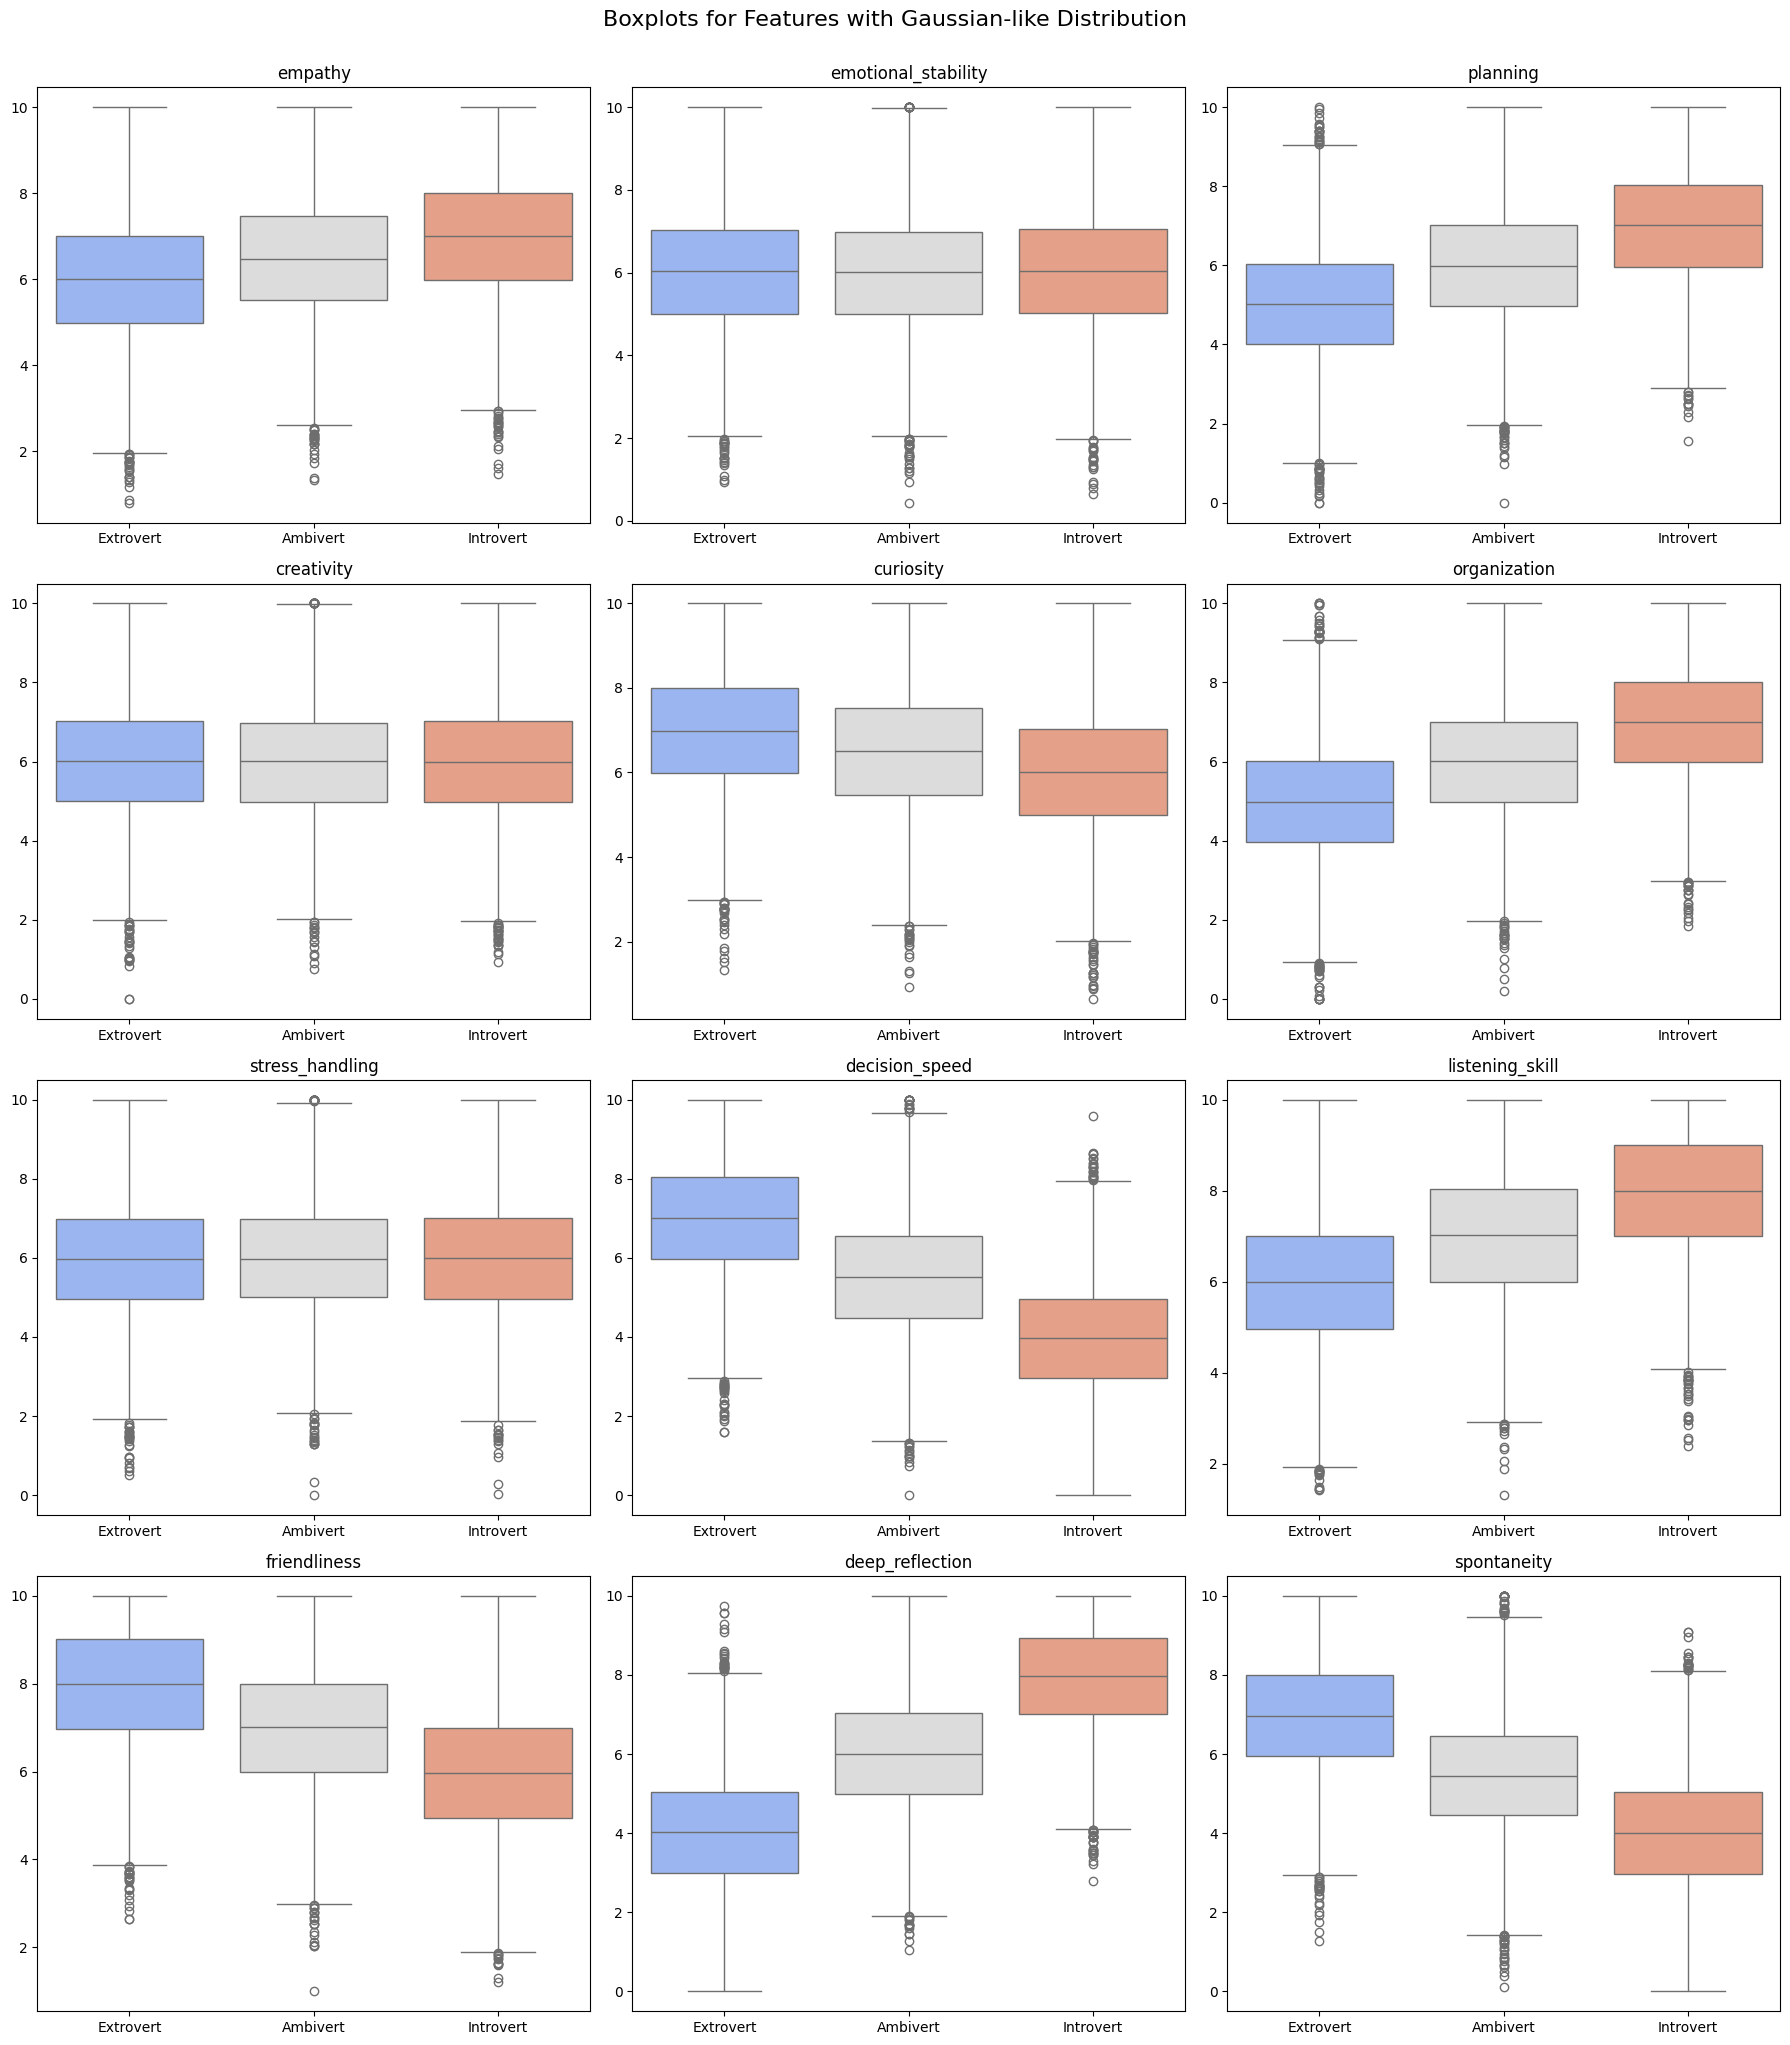

In [ ]:
gaussian_cols = [
    'empathy', 'emotional_stability', 'planning', 'creativity',
    'curiosity', 'organization', 'stress_handling', 'decision_speed',
    'listening_skill', 'friendliness', 'deep_reflection', 'spontaneity'
]

cols_to_plot = [col for col in gaussian_cols if col in df.columns]

n_cols = 3
n_rows = int(np.ceil(len(cols_to_plot) / n_cols))

plt.figure(figsize=(18, 5 * n_rows))

for i, col in enumerate(cols_to_plot):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(x='personality_type', y=col, data=df, hue='personality_type', legend=False, palette='coolwarm')

    plt.title(f'{col}', fontsize=12)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.suptitle('Boxplots for Features with Gaussian-like Distribution', y=1.02, fontsize=16)
plt.show()

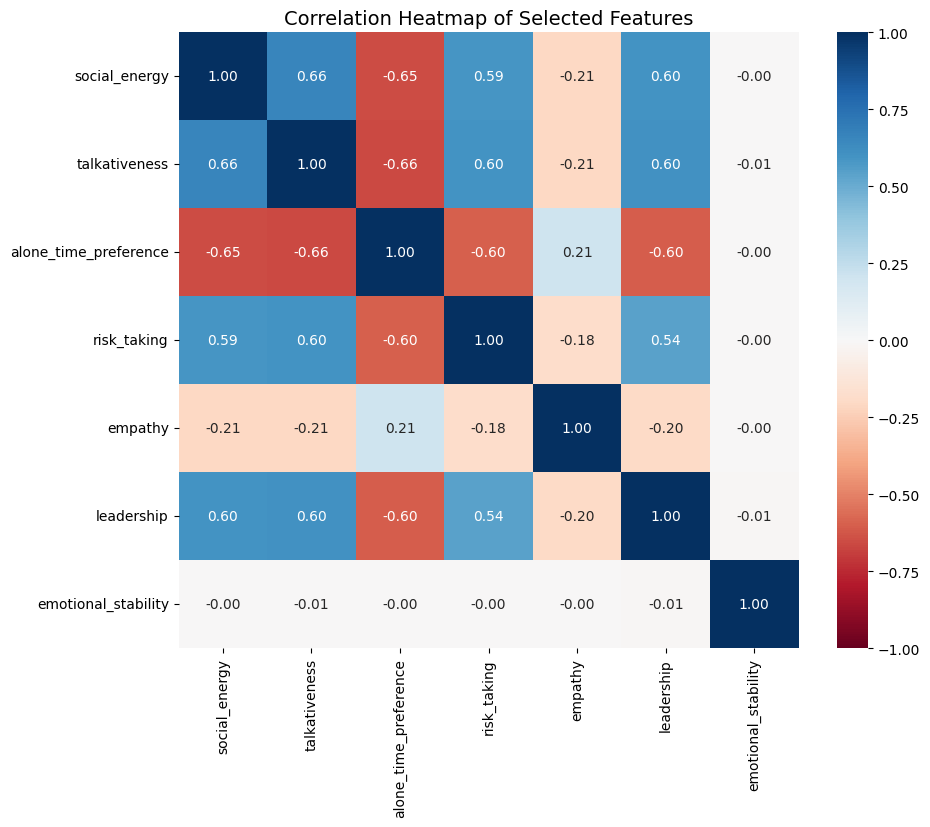

In [ ]:
subset_cols = ['social_energy', 'talkativeness', 'alone_time_preference',
               'risk_taking', 'empathy', 'leadership', 'emotional_stability']

corr_matrix = df[subset_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, cmap='RdBu', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Selected Features', fontsize=14)
plt.show()

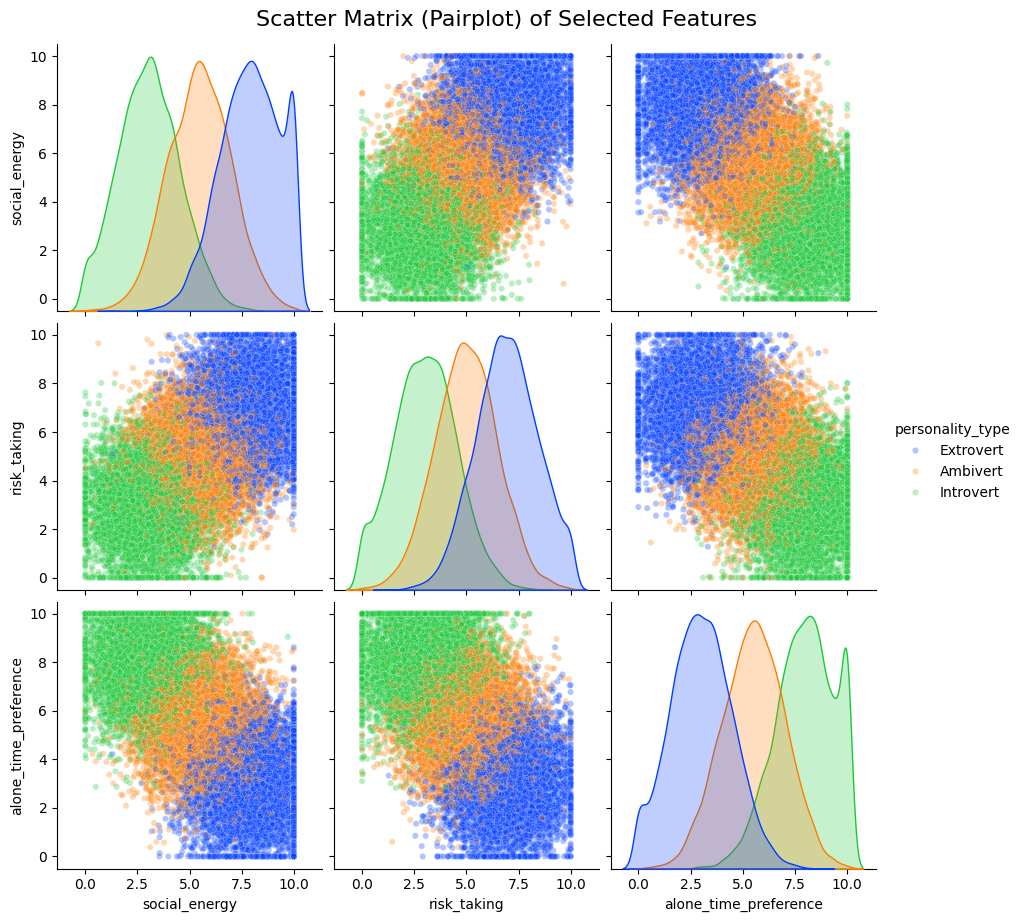

In [ ]:
pairplot_cols = ['social_energy', 'risk_taking', 'alone_time_preference', 'personality_type']


g = sns.pairplot(df[pairplot_cols], hue='personality_type', palette='bright',
                 plot_kws={'alpha': 0.3, 's': 20}, height=3)

g.fig.suptitle('Scatter Matrix (Pairplot) of Selected Features', y=1.02, fontsize=16)

plt.show()

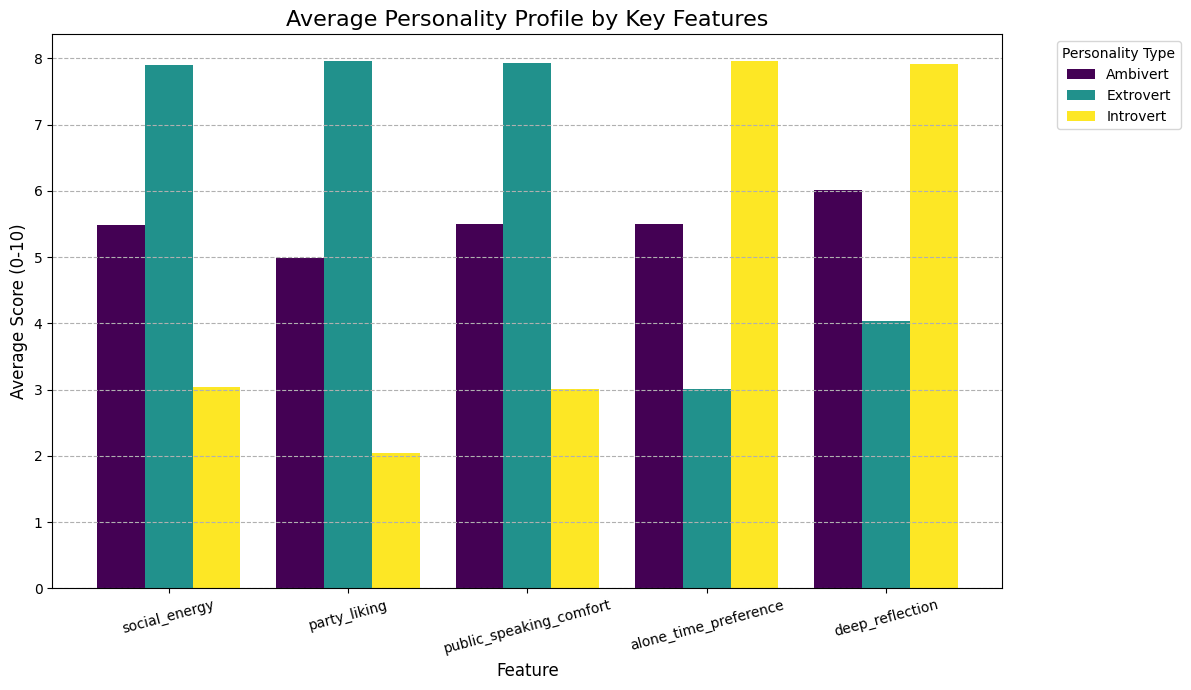

In [ ]:
profile_cols = ['social_energy', 'party_liking', 'public_speaking_comfort',
                'alone_time_preference', 'deep_reflection']

mean_profiles = df.groupby('personality_type')[profile_cols].mean()

ax = mean_profiles.T.plot(kind='bar', figsize=(12, 7), colormap='viridis', width=0.8)
plt.title('Average Personality Profile by Key Features', fontsize=16)
plt.ylabel('Average Score (0-10)', fontsize=12)
plt.xlabel('Feature', fontsize=12)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--')
plt.legend(title='Personality Type', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
X = df.drop('personality_type', axis=1)
y = df['personality_type']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data preprocessing complete.")

Data preprocessing complete.


In [ ]:
models = {
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [10, None]
        },
        'data': (X_train, X_test)
    },
    'SVM': {
        'model': SVC(),
        'params': {
            'C': [1, 10],
            'kernel': ['rbf', 'linear']
        },
        'data': (X_train_scaled, X_test_scaled)
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [5, 7],
            'weights': ['uniform', 'distance']
        },
        'data': (X_train_scaled, X_test_scaled)
    }
}

results = []
best_models = {}

for name, mp in models.items():
    print(f"\nTraining {name}...")

    X_tr, X_te = mp['data']

    grid = GridSearchCV(mp['model'], mp['params'], cv=5, n_jobs=-1)
    grid.fit(X_tr, y_train)

    best_model = grid.best_estimator_
    best_models[name] = best_model

    y_pred = best_model.predict(X_te)
    acc = accuracy_score(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy': acc,
        'Best Params': grid.best_params_
    })

    print("Best Params:", grid.best_params_)
    print("Accuracy:", acc)


Training Random Forest...
Best Params: {'max_depth': None, 'n_estimators': 100}
Accuracy: 0.996

Training SVM...
Best Params: {'C': 1, 'kernel': 'rbf'}
Accuracy: 0.9985

Training KNN...
Best Params: {'n_neighbors': 7, 'weights': 'uniform'}
Accuracy: 0.9975



Final Results:


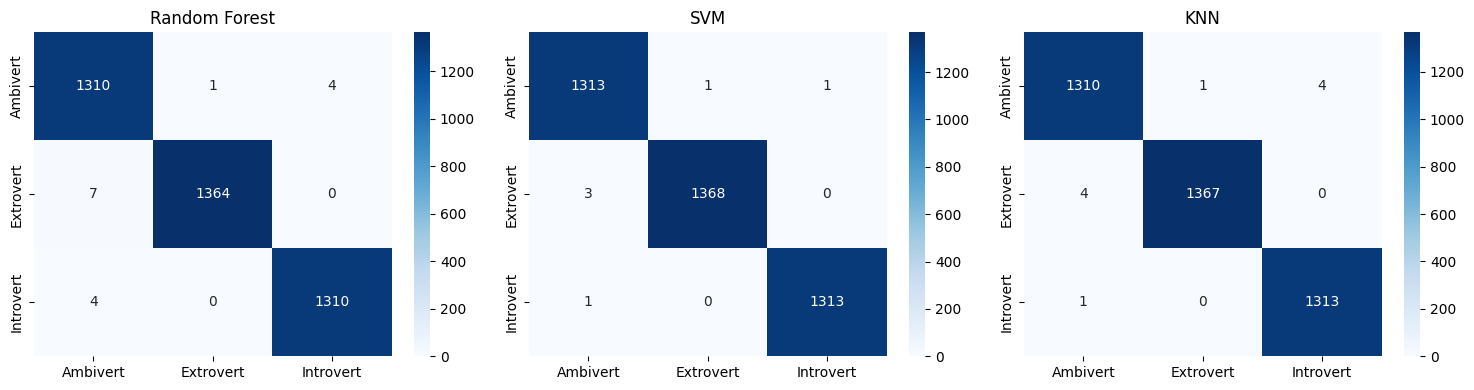

In [ ]:
results_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
print("\nFinal Results:")
results_df

plt.figure(figsize=(15,4))

for i, (name, model) in enumerate(best_models.items()):
    X_te = models[name]['data'][1]
    y_pred = model.predict(X_te)

    cm = confusion_matrix(y_test, y_pred)

    plt.subplot(1, 3, i+1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_,
                yticklabels=le.classes_)
    plt.title(name)

plt.tight_layout()
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]['Model']
best_model = best_models[best_model_name]
X_te = models[best_model_name]['data'][1]
print(f"\nBest Model: {best_model_name}")
y_pred_best = best_model.predict(X_te)
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=le.classes_
))


Best Model: SVM

Classification Report:
              precision    recall  f1-score   support

    Ambivert       1.00      1.00      1.00      1315
   Extrovert       1.00      1.00      1.00      1371
   Introvert       1.00      1.00      1.00      1314

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



In [ ]:
user_data = {}

print("Enter values between 0 to 10\n")

for col in X.columns:
    while True:
        try:
            value = float(input(f"{col}: "))

            if 0 <= value <= 10:
                user_data[col] = value
                break
            else:
                print("Please enter value between 0 and 10.")

        except:
            print("Invalid input. Enter a number.")

user_df = pd.DataFrame([user_data])

user_df = user_df[X.columns]

if best_model_name in ['SVM', 'KNN']:
    user_df_processed = scaler.transform(user_df)
else:
    user_df_processed = user_df


prediction = best_model.predict(user_df_processed)
result = le.inverse_transform(prediction)

print("\n Your Personality Type is:", result[0])

Enter values between 0 to 10

social_energy: 5
alone_time_preference: 6
talkativeness: 7
deep_reflection: 4
group_comfort: 8
party_liking: 5
listening_skill: 7
empathy: 6
creativity: 8
organization: 9
leadership: 4
risk_taking: 5
public_speaking_comfort: 6
curiosity: 7
routine_preference: 4
excitement_seeking: 5
friendliness: 5
emotional_stability: 6
planning: 5
spontaneity: 6
adventurousness: 5
reading_habit: 6
sports_interest: 5
online_social_usage: 6
travel_desire: 5
gadget_usage: 6
work_style_collaborative: 5
decision_speed: 6
stress_handling: 5

 Your Personality Type is: Ambivert
